# 05 — Feature Engineering

[Previous](./04_Categorical_Encoding.ipynb) | [Repository guide](../README.md) | [Next](./06_Feature_Selection.ipynb)

> This public copy includes the saved Kaggle outputs, so every table, chart, and score can be inspected on GitHub.

**Goal:** create useful new features from the existing columns, then test each feature group with the same model and the same five validation folds.

`solution.csv` is never read. IDs are excluded from the model.

### Read the setup

- `import` loads a Python tool; `as` gives it a short name.
- `pd` handles tables, `np` handles numerical calculations, and `plt` draws charts.
- The `sklearn` tools implement the methods explained in this chapter.


In [1]:
# Tables, numerical calculations, and charts.
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from joblib import parallel_backend
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# The column we want to predict: 1 = scored, 0 = missed.
TARGET = "is_scored"
# These identifier columns are excluded from the course's model inputs.
ID_COLUMNS = ["id", "kicker_id", "keeper_id", "match_id"]
# A fixed seed makes randomized splits and experiments repeatable.
RANDOM_STATE = 42

# Optional display settings: readable tables and chart grids.
pd.set_option("display.float_format", "{:.4f}".format)
plt.style.use("seaborn-v0_8-whitegrid")


### Load the competition data

Attach the competition under Kaggle's **Input** panel. `DATA_DIR` is its folder;
`pd.read_csv` opens a CSV as a table. `train` contains known answers; `test`
contains the rows we will eventually predict.

For Colab, upload the extracted CSV files and set `DATA_DIR` to `/content`;
the [repository guide](../README.md#colab) explains the output-path change.


In [3]:
DATA_DIR = "/kaggle/input/competitions/penalty-kick-outcome-prediction-challenge"

train = pd.read_csv(f"{DATA_DIR}/train.csv")
test = pd.read_csv(f"{DATA_DIR}/test.csv")

# Check that only train contains labels and both files have the same inputs.
assert TARGET in train and TARGET not in test
assert set(train.columns) - {TARGET} == set(test.columns)

print(f"Source: {DATA_DIR}")
print(f"Train: {train.shape} | Test: {test.shape}")


Source: /kaggle/input/competitions/penalty-kick-outcome-prediction-challenge
Train: (20000, 20) | Test: (6000, 19)
solution.csv: intentionally not loaded


## 1. What is feature engineering?

A **derived feature** is a new column calculated from existing columns. It expresses an idea in a form the model can use.

- **Difference:** compares opponents, e.g. player scoring form minus keeper saving form.
- **Ratio:** measures relative strength rather than raw size.
- **Indicator:** a `0/1` answer to a domain question, e.g. “is the game close?”
- **Interaction:** one condition changes another’s effect, e.g. player form under pressure.
- **Nonlinear/cyclical feature:** represents curves or repeating patterns, e.g. squared form or sine of match minute.

These row-by-row formulas use no target averages, so they can be created before CV. Features learned from group statistics would need to stay inside the pipeline.


## 2. Where did these candidates come from?

| Source | Dataset observation or football idea | Candidate examples |
|---|---|---|
| EDA / top-1 notebook | scoring rate changes with match state | `is_close_game`, `match_status`, losing/tied/winning |
| Domain reasoning | success depends on kicker relative to keeper | skill difference, ratio, product |
| Competition construction | pressure combines match type, minute, and score | `pressure_index`, low/extreme pressure |
| Interaction hypothesis | skill may matter differently under pressure | skill-gap × low-pressure, pressure × weak-player |
| Suggested generic alternatives | time may be curved/cyclical; effects may multiply | squares, sine/cosine minute, humidity interactions |
| Hidden-variable limitation | composure is unavailable | visible `skill_proxy`, clearly marked as imperfect |

We create even plausible alternatives that may fail. A feature is a candidate until OOF validation supports it.


In [4]:
FEATURE_GROUPS = {
    "Relative ability": ["skill_advantage", "foot_difference", "skill_ratio_share", "skill_proxy"],
    "Match state": [
        "is_close_game", "is_losing", "is_tied", "is_winning", "match_status",
        "home_crowd_aligned", "is_poor_pitch", "final_extra_time",
    ],
    "Pressure components": ["pressure_index", "low_pressure", "late_minute", "extreme_pressure", "is_weak_player"],
    "Problem interactions": [
        "skill_gap_x_low_pressure", "disaster_combo", "pressure_x_weak",
        "pressure_skill", "keeper_pressure", "late_close_game",
    ],
    "Nonlinear and cyclical": [
        "player_form_squared", "keeper_form_squared", "skill_to_keeper_ratio",
        "score_x_minute", "minute_sin", "minute_cos", "humidity_sq_weak",
        "skill_keeper_product", "humidity_minute_interaction",
    ],
    "Composure proxies": ["clutch_boost", "choke_penalty"],
}


def add_engineered_features(frame):
    result = frame.copy()
    player_pct = result["player_last5_scored_percent"] / 100
    keeper_pct = result["goalkeeper_last5_saved_percent"] / 100
    minute_norm = result["minute_taken"] / 120
    humidity_norm = result["weather_humidity"] / 100
    score_diff = result["current_score_diff"]
    # A comparison gives True/False; astype(float) turns it into 1.0/0.0.
    close_game = (score_diff.abs() <= 1).astype(float)

    # Relative-ability hypotheses.
    result["skill_advantage"] = result["player_last5_scored_percent"] - result["goalkeeper_last5_saved_percent"]
    result["foot_difference"] = result["strong_foot_usage"] - result["weak_foot_usage"]
    result["skill_ratio_share"] = player_pct / (player_pct + keeper_pct + 0.10)
    result["skill_proxy"] = (
        0.3 * result["strong_foot_usage"]
        + 0.2 * result["foot_difference"]
        + 0.5 * player_pct
    ).clip(0, 1)

    # Match state: whether the kicker's team is leading, tied, or losing.
    result["is_close_game"] = close_game
    result["is_losing"] = (score_diff < 0).astype(float)
    result["is_tied"] = (score_diff == 0).astype(float)
    result["is_winning"] = (score_diff > 0).astype(float)
    result["match_status"] = np.select(
        [(score_diff > 0), (score_diff == 0), (score_diff < 0)], [0.0, 1.0, 2.0], default=np.nan
    )
    result["home_crowd_aligned"] = (
        (result["home_or_away"] == "Home") & (result["crowd_behind_goal"] == "Home")
    ).astype(float)
    result["is_poor_pitch"] = (result["pitch_condition"] == "Poor").astype(float)
    result["final_extra_time"] = (
        (result["match_type"] == "Final") & (result["minute_taken"] > 90)
    ).astype(float)

    # Post-competition reconstruction of the problem's pressure idea.
    pressure_map = {"League": 0.2, "Cup": 0.4, "Playoff": 0.5, "Final": 0.6, "Friendly": 0.1}
    match_pressure = result["match_type"].map(pressure_map).fillna(0.3)
    score_pressure = 1.0 / (score_diff.abs() + 1)
    result["pressure_index"] = (0.5 * match_pressure + 0.25 * minute_norm + 0.25 * score_pressure).clip(0, 1)
    result["low_pressure"] = 1 - result["pressure_index"]
    result["late_minute"] = (minute_norm - 0.625).clip(0, 1)
    result["extreme_pressure"] = (result["pressure_index"] > 0.75).astype(float)
    result["is_weak_player"] = (player_pct < 0.4).astype(float)

    # Interactions: one condition changes the effect of another.
    result["skill_gap_x_low_pressure"] = (player_pct - keeper_pct) * result["low_pressure"]
    result["disaster_combo"] = result["late_minute"] * result["is_losing"] * result["is_poor_pitch"]
    result["pressure_x_weak"] = result["pressure_index"] * result["is_weak_player"]
    result["pressure_skill"] = close_game * result["player_last5_scored_percent"]
    result["keeper_pressure"] = (score_diff <= 0).astype(float) * result["goalkeeper_last5_saved_percent"]
    result["late_close_game"] = close_game * minute_norm

    # Generic suggested candidates: useful to test even when the result rejects them.
    result["player_form_squared"] = result["player_last5_scored_percent"] ** 2
    result["keeper_form_squared"] = result["goalkeeper_last5_saved_percent"] ** 2
    result["skill_to_keeper_ratio"] = result["player_last5_scored_percent"] / (
        result["goalkeeper_last5_saved_percent"] + 1
    )
    result["score_x_minute"] = score_diff * result["minute_taken"]
    result["minute_sin"] = np.sin(2 * np.pi * (result["minute_taken"] / 90))
    result["minute_cos"] = np.cos(4 * np.pi * (result["minute_taken"] / 90))
    result["humidity_sq_weak"] = (humidity_norm ** 2) * result["weak_foot_usage"]
    result["skill_keeper_product"] = player_pct * keeper_pct
    result["humidity_minute_interaction"] = humidity_norm * result["minute_sin"]

    # Composure is hidden; skill_proxy is a visible, imperfect substitute.
    result["clutch_boost"] = (result["skill_proxy"] > 0.7).astype(float) * result["extreme_pressure"]
    result["choke_penalty"] = (result["skill_proxy"] < 0.3).astype(float) * result["extreme_pressure"]
    return result

engineered = add_engineered_features(train.drop(columns=[TARGET]))
new_columns = []
for group_columns in FEATURE_GROUPS.values():
    new_columns.extend(group_columns)
print(f"Created {len(new_columns)} candidate features in {len(FEATURE_GROUPS)} groups.")


Created 34 candidate features in 6 groups.


,min,mean,max,missing_%
skill_advantage,-100.0000,-0.4440,100.0000,0.0000
foot_difference,-0.7470,0.2403,0.6170,0.0000
skill_ratio_share,0.0000,0.4366,0.9091,0.0000
skill_proxy,0.0000,0.4793,0.8909,0.0000
is_close_game,0.0000,0.4301,1.0000,0.0000
is_losing,0.0000,0.4276,1.0000,0.0000
is_tied,0.0000,0.1447,1.0000,0.0000
is_winning,0.0000,0.4277,1.0000,0.0000
match_status,0.0000,0.9999,2.0000,0.0000
home_crowd_aligned,0.0000,0.2066,1.0000,0.0000


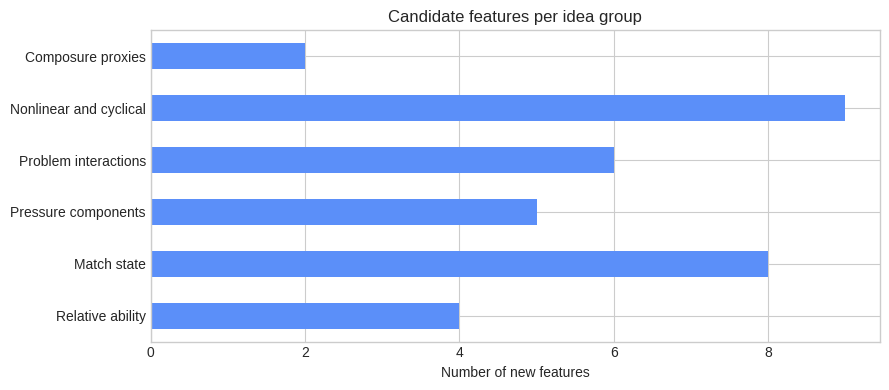

,player_last5_scored_percent,goalkeeper_last5_saved_percent,current_score_diff,minute_taken,skill_advantage,is_close_game,pressure_index,skill_gap_x_low_pressure,minute_sin
0,0,60,3,65.0000,-60,0.0000,0.2479,-0.4512,-0.9848
1,20,80,-2,1.0000,-60,0.0000,0.1854,-0.4888,0.0698
2,40,0,0,89.0000,40,1.0000,0.5354,0.1858,-0.0698
3,80,100,2,24.0000,-20,0.0000,0.3333,-0.1333,0.9945
4,40,40,0,46.0000,0,1.0000,0.5458,0.0000,-0.0698
5,20,40,-2,88.0000,-20,0.0000,0.3667,-0.1267,-0.1392


Example: raw player/keeper form becomes a relative skill feature; score and minute become match-pressure features.


In [5]:
preview = engineered[new_columns].agg(["min", "mean", "max"]).T
preview["missing_%"] = engineered[new_columns].isna().mean().mul(100)
display(preview)

group_sizes = pd.Series({group: len(columns) for group, columns in FEATURE_GROUPS.items()})
ax = group_sizes.plot.barh(figsize=(9, 4), color="#5b8ff9", title="Candidate features per idea group")
ax.set(xlabel="Number of new features", ylabel="")
plt.tight_layout()
plt.show()

example_columns = [
    "player_last5_scored_percent", "goalkeeper_last5_saved_percent", "current_score_diff", "minute_taken",
    "skill_advantage", "is_close_game", "pressure_index", "skill_gap_x_low_pressure", "minute_sin",
]
display(engineered[example_columns].head(6))
print("Example: raw player/keeper form becomes a relative skill feature; score and minute become match-pressure features.")


## 3. Fair comparison

Every experiment keeps the same original columns, logistic model, threshold, and five folds. It adds only one candidate group; the final experiment adds all groups.

This is an **ablation-style comparison**: changing one group tells us which idea caused the difference. OOF means each row is predicted by a model that did not train on it.


In [6]:
X_original = train.drop(columns=[TARGET] + ID_COLUMNS)
y = train[TARGET].astype(int)
X_engineered = add_engineered_features(X_original)

categorical_columns = X_original.select_dtypes(exclude=np.number).columns.tolist()
original_numerical = X_original.select_dtypes(include=np.number).columns.tolist()
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)


def make_pipeline(numerical_columns):
    preprocessor = ColumnTransformer([
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler()),
        ]), numerical_columns),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(handle_unknown="ignore")),
        ]), categorical_columns),
    ])
    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)),
    ])


In [7]:
experiments = {"Original features": []}
experiments.update({f"+ {group}": columns for group, columns in FEATURE_GROUPS.items()})
experiments["+ All engineered"] = new_columns

rows = []
for name, added_columns in experiments.items():
    selected_columns = X_original.columns.tolist() + added_columns
    numerical_columns = original_numerical + added_columns
    model = make_pipeline(numerical_columns)

    with parallel_backend("threading"):
        probabilities = cross_val_predict(
            model, X_engineered[selected_columns], y, cv=cv,
            method="predict_proba", n_jobs=-1,
        )[:, 1]

    predictions = (probabilities >= 0.5).astype(int)
    fold_f1 = [f1_score(y.iloc[index], predictions[index]) for _, index in cv.split(X_original, y)]
    rows.append({
        "feature_set": name,
        "new_features": len(added_columns),
        "f1": f1_score(y, predictions),
        "f1_std": np.std(fold_f1, ddof=1),
        "precision": precision_score(y, predictions),
        "recall": recall_score(y, predictions),
        "accuracy": accuracy_score(y, predictions),
        "roc_auc": roc_auc_score(y, probabilities),
    })

results = pd.DataFrame(rows).sort_values("f1", ascending=False).reset_index(drop=True)
display(results)


,feature_set,new_features,f1,f1_std,precision,recall,accuracy,roc_auc
0,+ All engineered,34,0.8847,0.0061,0.8916,0.8779,0.8970,0.9625
1,+ Match state,8,0.8734,0.0039,0.8819,0.8651,0.8871,0.9562
2,+ Problem interactions,6,0.8552,0.0084,0.8587,0.8517,0.8702,0.9469
3,+ Nonlinear and cyclical,9,0.8531,0.0066,0.8601,0.8462,0.8689,0.9428
4,+ Pressure components,5,0.8523,0.0057,0.8547,0.8500,0.8675,0.9435
5,+ Composure proxies,2,0.8488,0.0054,0.8530,0.8447,0.8646,0.9404
6,+ Relative ability,4,0.8486,0.0051,0.8537,0.8435,0.8645,0.9404
7,Original features,0,0.8482,0.0054,0.8530,0.8435,0.8641,0.9404


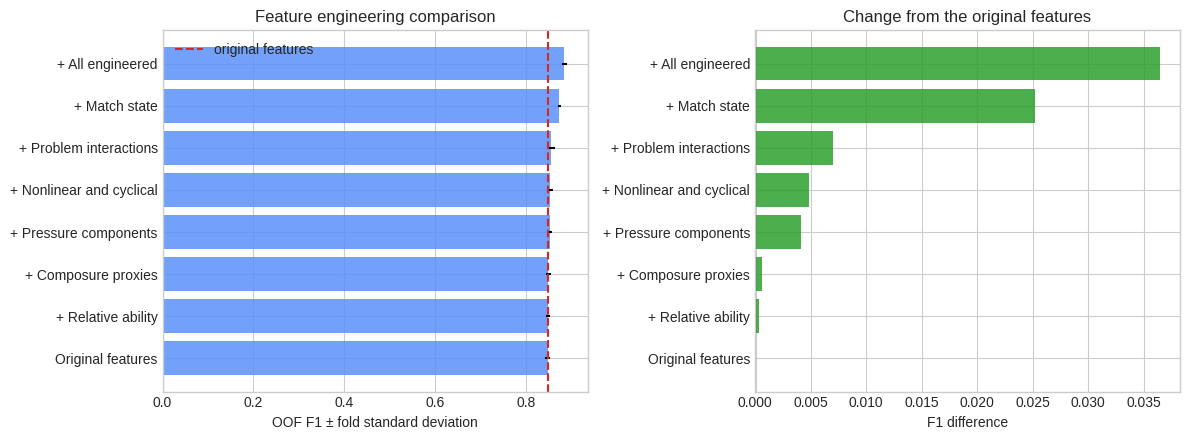

In [8]:
baseline_f1 = results.loc[results["feature_set"].eq("Original features"), "f1"].iloc[0]
ordered = results.sort_values("f1")

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
axes[0].barh(ordered["feature_set"], ordered["f1"], xerr=ordered["f1_std"], color="#5b8ff9", alpha=.85)
axes[0].axvline(baseline_f1, color="#d62728", linestyle="--", label="original features")
axes[0].set(title="Feature engineering comparison", xlabel="OOF F1 ± fold standard deviation", ylabel="")
axes[0].legend()

deltas = ordered["f1"] - baseline_f1
colors = np.where(deltas >= 0, "#2ca02c", "#d62728")
axes[1].barh(ordered["feature_set"], deltas, color=colors, alpha=.85)
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set(title="Change from the original features", xlabel="F1 difference", ylabel="")
plt.tight_layout()
plt.show()


## 4. How the decision is made

First compare every group with the original-feature F1. Then compare the gain with `f1_std`, the ordinary variation between folds. More features are kept only when their improvement is large enough to be credible.


In [9]:
best = results.iloc[0]
baseline = results.loc[results["feature_set"].eq("Original features")].iloc[0]
gain = best["f1"] - baseline["f1"]

print(f"Best point estimate: {best['feature_set']} | F1 {best['f1']:.4f}")
print(f"Gain over original features: {gain:+.4f}")
if best["feature_set"] == "Original features" or gain < baseline["f1_std"]:
    print("Decision: no clear gain beyond fold variation; keep the original features for now.")
else:
    print("Decision: keep the best feature group and confirm it with repeated cross-validation later.")


Best point estimate: + All engineered | F1 0.8847
Gain over original features: +0.0365
Decision: keep the best feature group and confirm it with repeated cross-validation later.


## Other alternatives

- **Automatic polynomial expansion:** creates every pair/product; broad but can explode the feature count.
- **Binning / quantile binning:** converts numbers into ranges; interpretable but loses detail.
- **Log features:** compress positive skew; Notebook 03 tests whether that transformation helps.
- **Aggregations:** player/keeper/match history; unavailable because the supplied IDs are unique.
- **Group averages:** must be learned inside validation to avoid leakage.

Unlike the previous draft, the notebook now actually creates the suggested ratios, powers, cycles, pressure components, and problem interactions. The table shows which hypotheses validation accepts.


In [10]:
# Path is used only to name the files saved in Kaggle's Output panel.
from pathlib import Path

results_dir = Path("/kaggle/working")
results_dir.mkdir(parents=True, exist_ok=True)
output_path = results_dir / "05_feature_engineering.csv"
results.to_csv(output_path, index=False)
print(f"Saved: {output_path}")


Saved: /kaggle/working/05_feature_engineering.csv


## Why the feature-engineering decision is justified

**Technical evidence:** each idea group is compared with identical OOF folds; the best group’s gain is measured against fold variation, and rejected suggestions remain visible in the table.

**Theoretical reason:** logistic regression learns additive straight-line effects. Relative skill, pressure, indicators, curves, and interactions expose relationships it cannot construct on its own. We carry forward only the validated set, not every imaginable feature.
